In [52]:
import torch
from scipy.stats import shapiro, normaltest, anderson, kstest

In [53]:
def load_fwd(single_file, multi_path):
    single = torch.load(single_file)
    m0 = torch.load(multi_path + '/rank0.pt')
    m4 = torch.load(multi_path + '/rank4.pt')
    distr = m0 + m4
    single_idx = {n: i for (i, (n, _)) in enumerate(single) if n.startswith('batch_0.')}

    s = {}
    d = {}
    for (n, t) in distr:
        if n in single_idx:
            s[n] = single[single_idx[n]][1]
            d[n] = t

    return s, d, single, distr

In [54]:
s, d, _, _ = load_fwd('single-fp16.pt', 'fp16')

In [59]:
t1 = s['batch_0.layer_1.attn'].view(-1).to(torch.float32).numpy()
t2 = d['batch_0.layer_1.attn'].view(-1).to(torch.float32).numpy()

In [66]:
shapiro((t1 - t2) * 1).pvalue

4.533000763218674e-236

In [73]:
m1 = (t1 - t2) > 6e-5
mskd1 = (t1-t2)[m1]

In [75]:
mskd1

array([6.1035156e-05, 6.1035156e-05, 1.2207031e-04, ..., 6.1035156e-05,
       6.1035156e-05, 6.1035156e-05], dtype=float32)

(array([1.528e+03, 0.000e+00, 0.000e+00, ..., 0.000e+00, 0.000e+00,
        1.000e+00]),
 array([6.10351562e-05, 6.10534698e-05, 6.10717761e-05, ...,
        2.44103998e-04, 2.44122319e-04, 2.44140625e-04]),
 <BarContainer object of 10000 artists>)

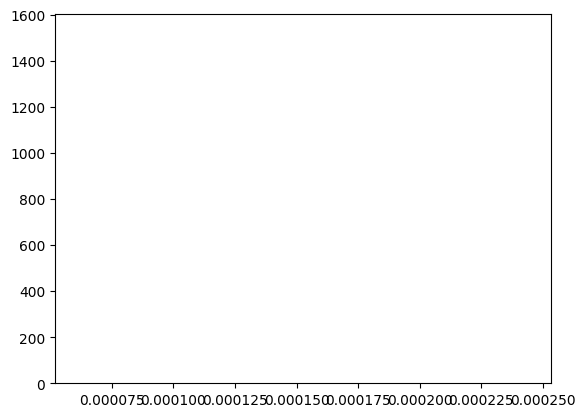

In [76]:
import matplotlib.pyplot as plt
plt.hist(mskd1, bins=10000)

In [39]:
mask = (t1 > 2**(-126)) & (t2 > 2**(-126))
t1 = t1[mask]
t2 = t2[mask]
rerr = (t1 - t2) / t1

(array([1.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        1.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 1.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        2.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 1.000000e+00, 0.000000e+00,
        1.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 0.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 1.000000e+00, 0.000000e+00, 0.000000e+00,
        0.000000e+00, 1.000000e+00, 0.000000e+00, 1.000000e+00,
        1.000000e+00, 3.000000e+00, 2.000000e+00, 4.000000e+00,
        5.000000e+00, 3.000000e+00, 1.30

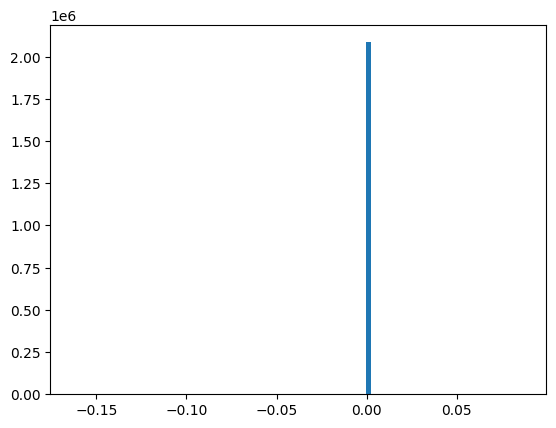

In [18]:
import matplotlib.pyplot as plt
plt.hist(rerr, bins=100)

In [41]:
res = shapiro(t1 - t2)
res2 = normaltest(t1 - t2)
res3 = anderson(t1 - t2)
res4 = kstest(t1 - t2, 'norm')

/opt/miniconda3/envs/megatron/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:573: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 4194304.
  res = hypotest_fun_out(*samples, **kwds)
/opt/miniconda3/envs/megatron/lib/python3.10/site-packages/scipy/stats/_morestats.py:2259: RuntimeWarning: divide by zero encountered in divide
  w = (y - xbar) / s
/opt/miniconda3/envs/megatron/lib/python3.10/site-packages/scipy/stats/_morestats.py:2259: RuntimeWarning: invalid value encountered in divide
  w = (y - xbar) / s


In [42]:
res.statistic, res.pvalue

(0.3102510891526563, 4.533000763218674e-236)

In [43]:
res2.statistic, res2.pvalue

(nan, nan)

In [44]:
res3.statistic, res3.critical_values

(nan, array([0.576, 0.656, 0.787, 0.918, 1.092]))

In [45]:
res4.statistic, res4.pvalue

(0.4999670674267484, 0.0)

In [61]:
diff = t1 - t2
diff.mean(), 1 / diff.std()

(1.2333459e-09, 233690.08745294102)

In [63]:
(diff * 233690).mean(), (diff * 233690).std()

(0.00028822059633171193, 0.9999998304635676)

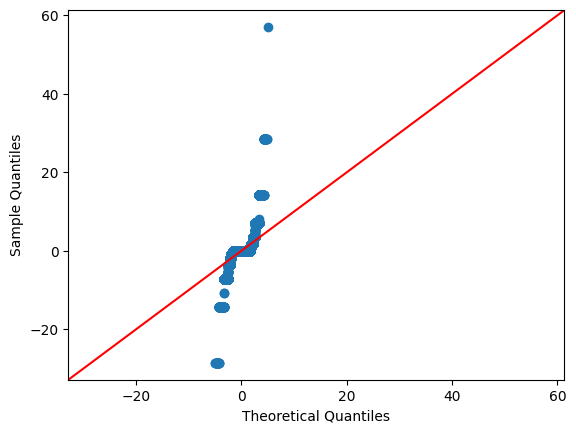

In [62]:
import numpy as np 
import statsmodels.api as sm 
import pylab as py 
sm.qqplot((t1 - t2) * 233690, line ='45') 
py.show()

In [24]:
_, bug, _, _ = load_fwd('single-fp32.pt', 'buggy-fp16')

In [25]:
bt = bug['batch_0.layer_1.attn'].view(-1).numpy()

In [26]:
(t1-bt).mean()

7.223882e-05

In [12]:
s2, p2 = shapiro(t1 - bt)

/opt/miniconda3/envs/megatron/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:573: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 4194304.
  res = hypotest_fun_out(*samples, **kwds)


In [13]:
s2, p2

(0.5083405312522195, 1.1503408212983657e-222)

In [22]:
rerr.mean()

-1.7404286e-08

In [49]:
import numpy as np
a = np.random.randn(100000)*1000
res = shapiro(a)
res.statistic, res.pvalue

/opt/miniconda3/envs/megatron/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:573: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 100000.
  res = hypotest_fun_out(*samples, **kwds)


(0.9999843932725554, 0.9810485067228515)

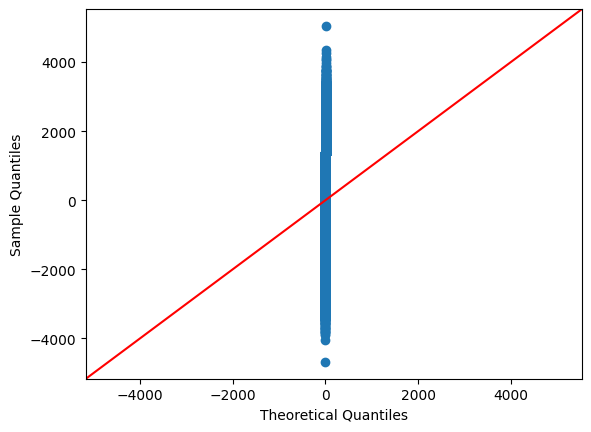

In [50]:
sm.qqplot(a, line ='45') 
py.show()

In [51]:
help(sm.qqplot)

Help on function qqplot in module statsmodels.graphics.gofplots:

qqplot(data, dist=<scipy.stats._continuous_distns.norm_gen object at 0x770340102a70>, distargs=(), a=0, loc=0, scale=1, fit=False, line=None, ax=None, **plotkwargs)
    Q-Q plot of the quantiles of x versus the quantiles/ppf of a distribution.
    
    Can take arguments specifying the parameters for dist or fit them
    automatically. (See fit under Parameters.)
    
    Parameters
    ----------
    data : array_like
        A 1d data array.
    dist : callable
        Comparison distribution. The default is
        scipy.stats.distributions.norm (a standard normal).
    distargs : tuple
        A tuple of arguments passed to dist to specify it fully
        so dist.ppf may be called.
    a : float
        Offset for the plotting position of an expected order statistic, for
        example. The plotting positions are given by (i - a)/(nobs - 2*a + 1)
        for i in range(0,nobs+1)
    loc : float
        Location par